# Notebook 07 – Error analysis: model sai ở đâu và vì sao?

**Mục tiêu:** hiểu *kiểu lỗi* của model tốt nhất, chứ không chỉ nhìn một con số macro-F1. Đây là phần mà người chấm báo cáo và reviewer SemEval đọc kỹ nhất.

**Nội dung**
1. Chọn hệ thống tốt nhất (theo OOF) cho A và cho B
2. Confusion matrix và các kiểu lỗi của B
3. Lỗi theo đặc điểm của comment: độ dài, có nhắc nhóm bị nhắm không, tôn giáo, câu hỏi...
4. Lỗi theo video
5. So với TF-IDF: mẫu nào cả hai đều sai (= mẫu khó thật sự)?
6. Comment trùng nội dung nhưng khác nhãn (giới hạn trên của bài toán)
7. Lỗi "tự tin": model chắc chắn nhưng vẫn sai
8. Xuất file lỗi để cả nhóm đọc tay

⚠️ Notebook này in ra nguyên văn một số comment có nội dung xúc phạm, vì đó là dữ liệu của bài toán.

In [1]:
# Chạy trên Kaggle? Ô này chép bộ dữ liệu + code (dataset bạn đã upload) sang /kaggle/working
# vì /kaggle/input chỉ đọc được, không ghi được. Trên máy nhà ô này tự bỏ qua.
import os
import shutil
from pathlib import Path

if Path("/kaggle/input").exists():
    bundle = next(Path("/kaggle/input").rglob("SemEval2027_Task8")).parent
    work = Path("/kaggle/working/sqe")
    if not work.exists():
        shutil.copytree(bundle, work)
    os.chdir(work / "SemEval2027_Task8" / "notebooks")
    print("Kaggle – thư mục làm việc:", Path.cwd())

Kaggle – thư mục làm việc: /kaggle/working/sqe/SemEval2027_Task8/notebooks


In [2]:
import re
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sqe").exists())
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, f1_score

from sqe.data import TASKS, load_en
from sqe.metrics import fold_scores
from sqe.results import OOF_DIR, load_oof

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 160)
df = load_en()
OUT = ROOT / "outputs" / "error_analysis"
OUT.mkdir(parents=True, exist_ok=True)

## 1. Chọn hệ thống tốt nhất cho mỗi subtask

Quét mọi file OOF của các model fine-tune (notebook 03–05), xếp hạng theo macro-F1 trung bình 5 fold.

In [3]:
SKIP = ("random_", "majority_", "tfidf")
cands = []
for f in OOF_DIR.glob("*.csv"):
    name, t = f.stem.rsplit("_", 1)
    if t in "AB" and not f.stem.startswith(SKIP):
        sc = fold_scores(load_oof(name, t), TASKS[t][1])
        cands.append({"subtask": t, "name": name, "macro_f1": sc.macro_f1.mean(), "std": sc.macro_f1.std(ddof=0)})
cands = pd.DataFrame(cands).sort_values(["subtask", "macro_f1"], ascending=[True, False])
BEST = {t: cands[cands.subtask == t].iloc[0]["name"] for t in "AB"}
display(cands.groupby("subtask").head(5))
print("Phân tích:", BEST)

oof = {t: load_oof(BEST[t], t).merge(df, on=["StereoQueerEval_id", "video_id", "fold"]) for t in "AB"}
tfidf = {t: load_oof("tfidf_comment", t).set_index("StereoQueerEval_id")["y_pred"] for t in "AB"}

,subtask,name,macro_f1,std
17,A,mt_twhate_comment_bias,0.736,0.011
19,A,mt_twhate_comment,0.735,0.011
10,A,mtcw_twhate_comment_bias,0.735,0.011
6,A,twhate_comment,0.733,0.012
18,A,twhate_comment_bias,0.731,0.012
20,B,mt_twhate_comment,0.601,0.026
5,B,mtcw_twhate_comment,0.598,0.022
13,B,mt_twhate_comment_bias,0.596,0.016
21,B,mtcw_twhate_comment_bias,0.596,0.018
9,B,twhate_comment_bias,0.590,0.011


Phân tích: {'A': 'mt_twhate_comment_bias', 'B': 'mt_twhate_comment'}


## 2. Confusion matrix và các kiểu lỗi

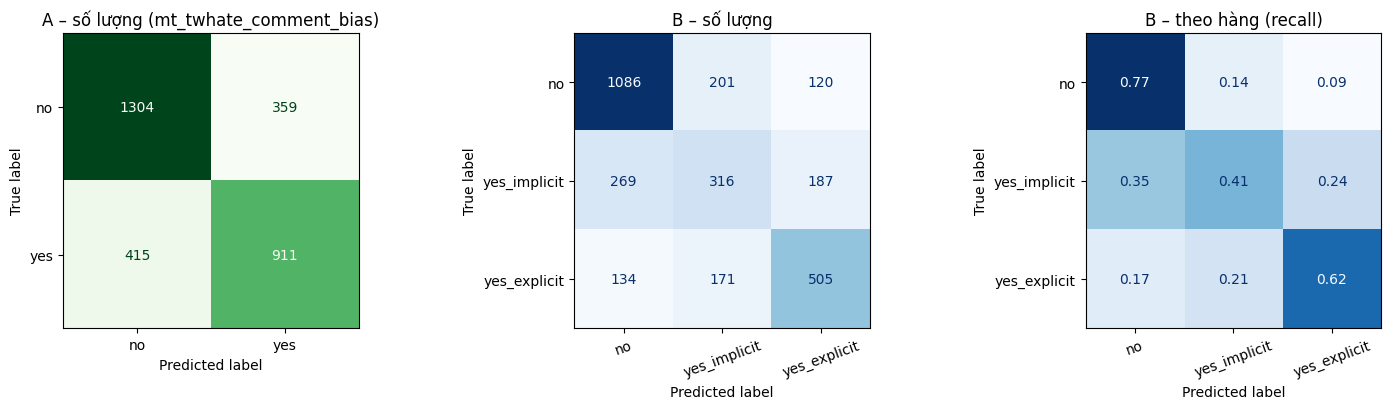

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ConfusionMatrixDisplay.from_predictions(oof["A"].y_true, oof["A"].y_pred, labels=TASKS["A"][1],
                                        ax=axes[0], colorbar=False, cmap="Greens")
axes[0].set_title(f"A – số lượng ({BEST['A']})")
for ax, norm, title in [(axes[1], None, "số lượng"), (axes[2], "true", "theo hàng (recall)")]:
    ConfusionMatrixDisplay.from_predictions(oof["B"].y_true, oof["B"].y_pred, labels=TASKS["B"][1], normalize=norm,
                                            values_format=".2f" if norm else "d", ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"B – {title}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(OUT / "confusion_best.png", dpi=150)
plt.show()

In [5]:
def error_type_B(y, p):
    if y == p:
        return "đúng"
    if y != "no" and p != "no":
        return "nhầm implicit ↔ explicit"
    if y != "no" and p == "no":
        return "bỏ sót hate (hate → no)"
    return "báo nhầm hate (no → hate)"


oof["B"]["error_type"] = [error_type_B(y, p) for y, p in zip(oof["B"].y_true, oof["B"].y_pred)]
et = oof["B"]["error_type"].value_counts()
errs = et.drop("đúng")
pd.DataFrame({"số mẫu": errs, "% trong tổng số lỗi": (errs / errs.sum() * 100).round(1)})

,số mẫu,% trong tổng số lỗi
error_type,,
bỏ sót hate (hate → no),403,37.2
nhầm implicit ↔ explicit,358,33.1
báo nhầm hate (no → hate),321,29.7


Nếu nhóm "nhầm implicit ↔ explicit" chiếm phần lớn thì điều đó khớp với EDA: hai lớp này gần như không tách được về mặt từ vựng. Mỗi lỗi kiểu này làm giảm F1 của *cả hai* lớp hate cùng lúc, nên ảnh hưởng mạnh đến macro-F1.

## 3. Lỗi theo đặc điểm của comment

Dùng lại các đặc trưng regex từ EDA (notebook 01). Với mỗi nhóm, tính macro-F1 của B và độ chính xác (accuracy). Nhóm nhỏ (n < 100) cho con số dao động nhiều, nên đọc kèm cột n.

In [6]:
FEATURES = {
    "nhắc identity (gay/trans/lgbt…)": r"\b(?:gays?|lesbians?|bi|bisexuals?|trans|transgender\w*|transsexual\w*|trans(?:wom[ae]n|m[ae]n)|queers?|homo\w*|lgbt\w*|non-?binary|intersex|asexual|tranny|trannies|fag\w*|dykes?)\b",
    "đại từ he/she/him/her": r"\b(?:he|him|his|she|her|hers)\b",
    "tôn giáo (god, sin, bible…)": r"\b(?:god|jesus|christ\w*|bible|sin|sins|sinful|sinner\w*|lord|church|allah|satan\w*|abomination|pray\w*|repent\w*|hell)\b",
    "sinh học (biology, dna, xx/xy…)": r"\b(?:biolog\w*|dna|chromosome\w*|xx|xy|genitals?|real (?:wom[ae]n|m[ae]n)|biological\w*)\b",
    "câu hỏi (?)": r"\?",
    "cười (😂, lol, lmao)": r"😂|🤣|\blol\b|\blmao\b|\bhaha\w*",
}
B = oof["B"]
labels_B = TASKS["B"][1]


def group_stats(mask):
    g = B[mask]
    return {"n": len(g), "macro_f1_B": f1_score(g.y_true, g.y_pred, labels=labels_B, average="macro", zero_division=0),
            "accuracy_B": (g.y_true == g.y_pred).mean(), "% nhãn hate": (g.y_true != "no").mean() * 100}


rows = []
for name, pat in FEATURES.items():
    has = B.yt_comment.str.lower().str.contains(pat, regex=True).to_numpy()
    rows.append({"đặc điểm": name, "có/không": "có", **group_stats(has)})
    rows.append({"đặc điểm": name, "có/không": "không", **group_stats(~has)})
pd.DataFrame(rows).set_index(["đặc điểm", "có/không"]).round(3)

n  macro_f1_B  accuracy_B  \
đặc điểm                        có/không                                 
nhắc identity (gay/trans/lgbt…) có        1108       0.562       0.689   
                                không     1881       0.598       0.608   
đại từ he/she/him/her           có         618       0.576       0.647   
                                không     2371       0.606       0.636   
tôn giáo (god, sin, bible…)     có         374       0.633       0.663   
                                không     2615       0.594       0.634   
sinh học (biology, dna, xx/xy…) có          90       0.488       0.511   
                                không     2899       0.605       0.642   
câu hỏi (?)                     có         486       0.578       0.632   
                                không     2503       0.606       0.639   
cười (😂, lol, lmao)             có         129       0.585       0.605   
                                không     2860       0.602       0.640   

                                          % nhãn hate  
đặc điểm                        có/không               
nhắc identity (gay/trans/lgbt…) có             42.419  
                                không          59.117  
đại từ he/she/him/her           có             49.029  
                                không          53.943  
tôn giáo (god, sin, bible…)     có             65.508  
                                không          51.128  
sinh học (biology, dna, xx/xy…) có             73.333  
                                không          52.294  
câu hỏi (?)                     có             49.177  
                                không          53.656  
cười (😂, lol, lmao)             có             52.713  
                                không          52.937

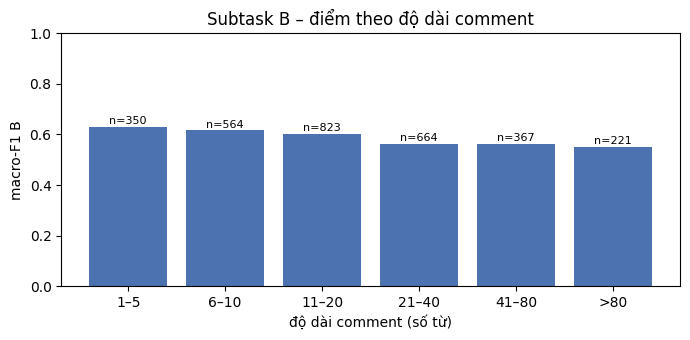

,số từ,n,macro_f1_B,accuracy_B,% nhãn hate
0,1–5,350,0.631,0.631,63.714
1,6–10,564,0.617,0.645,53.014
2,11–20,823,0.604,0.644,51.033
3,21–40,664,0.564,0.623,53.916
4,41–80,367,0.564,0.629,49.591
5,>80,221,0.552,0.665,45.249


In [7]:
n_words = B.yt_comment.str.split().str.len()
bins = pd.cut(n_words, [0, 5, 10, 20, 40, 80, 10_000], labels=["1–5", "6–10", "11–20", "21–40", "41–80", ">80"])
len_tab = pd.DataFrame([{"số từ": b, **group_stats((bins == b).to_numpy())} for b in bins.cat.categories])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(len_tab["số từ"], len_tab["macro_f1_B"], color="#4c72b0")
for i, r in len_tab.iterrows():
    ax.text(i, r.macro_f1_B + 0.01, f"n={r.n}", ha="center", fontsize=8)
ax.set_xlabel("độ dài comment (số từ)")
ax.set_ylabel("macro-F1 B")
ax.set_ylim(0, 1)
ax.set_title("Subtask B – điểm theo độ dài comment")
plt.tight_layout()
plt.savefig(OUT / "f1_by_length.png", dpi=150)
plt.show()
len_tab.round(3)

## 4. Lỗi theo video

Test chứa các video *mới*. Nếu model làm tốt ở một số video nhưng rất tệ ở số khác, điểm test sẽ phụ thuộc nhiều vào việc tập test rơi vào chủ đề nào.

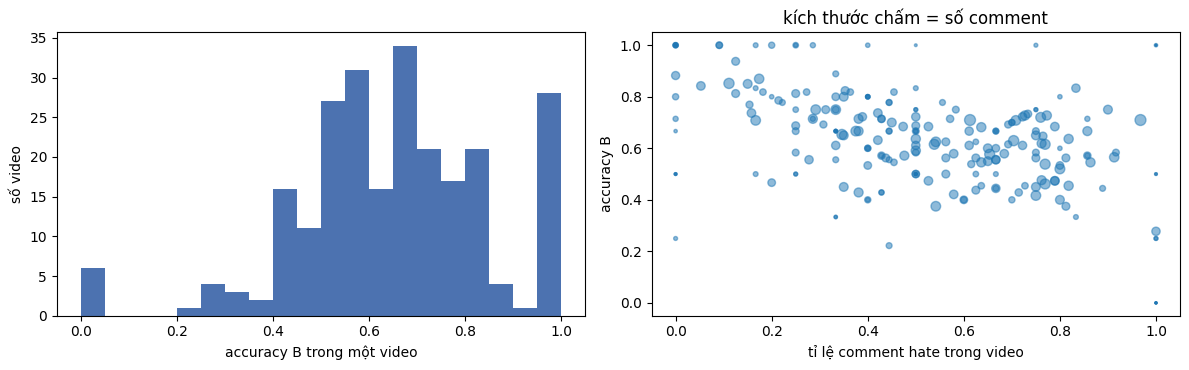

10 video (≥ 10 comment) model làm tệ nhất:


,n,title,accuracy,hate_rate
video_id,,,,
EN_v118,18,LGBT Content aimed at children to be banned in Hungary - [CHANNEL],0.278,1.000
EN_v062,16,Christine Quinn: Gavin Newsom's shift in trans debate is 'disgusting',0.375,0.812
EN_v044,24,Supreme Court lets Trump block transgender people from choosing passport sex markers,0.375,0.542
EN_v073,10,The culture of coming out on YouTube,0.400,0.400
EN_v099,20,Democrat responds to criticism of his comments about transgender athletes,0.400,0.800
EN_v122,10,Joel Osteen: scripture clear on gay marriage,0.400,0.700
EN_v078,15,Trump mocks transgender athletes in women's sports | [CHANNEL],0.400,0.600
EN_v189,10,"Lawyer in Saudi trans student's suicide note had embassy links, [CHANNEL] finds | [CHANNEL]",0.400,0.600
EN_v103,24,SE Cupp: Dawn Staley's position on Trans athletes is red meat for the right,0.417,0.750


In [8]:
vid = B.groupby("video_id").agg(n=("y_true", "size"), title=("yt_title", "first"),
                                accuracy=("error_type", lambda s: (s == "đúng").mean()),
                                hate_rate=("y_true", lambda s: (s != "no").mean()))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(vid.accuracy, bins=20, color="#4c72b0")
axes[0].set_xlabel("accuracy B trong một video")
axes[0].set_ylabel("số video")
axes[1].scatter(vid.hate_rate, vid.accuracy, s=vid.n * 2, alpha=0.5)
axes[1].set_xlabel("tỉ lệ comment hate trong video")
axes[1].set_ylabel("accuracy B")
axes[1].set_title("kích thước chấm = số comment")
plt.tight_layout()
plt.show()
print("10 video (≥ 10 comment) model làm tệ nhất:")
vid[vid.n >= 10].sort_values("accuracy").head(10)

## 5. So với TF-IDF: mẫu khó thật sự

Chia mẫu thành 4 nhóm theo việc hai model đúng hay sai. Nhóm **cả hai đều sai** là những mẫu khó với cả cách "đếm từ" lẫn cách "hiểu ngữ cảnh".

In [9]:
agree = {}
for t in "AB":
    o = oof[t]
    tr_ok = o.y_true == o.y_pred
    tf_ok = o.y_true.to_numpy() == tfidf[t].reindex(o.StereoQueerEval_id).to_numpy()
    agree[t] = pd.crosstab(pd.Series(tr_ok.values, name="transformer đúng"), pd.Series(tf_ok, name="TF-IDF đúng"))
    print(f"Subtask {t}")
    display(agree[t])

Subtask A


TF-IDF đúng,False,True
transformer đúng,,
False,441,333
True,444,1771


Subtask B


TF-IDF đúng,False,True
transformer đúng,,
False,733,349
True,580,1327


## 6. Comment trùng nội dung nhưng khác nhãn

EDA đã thấy có những comment gần như giống hệt nhau (ví dụ "That's a man") nhưng được gán nhãn khác nhau tuỳ video. Với input chỉ có comment, model *không thể* đúng cả hai, nên đây là một phần lỗi không tránh được.

In [10]:
def norm_text(s):
    s = re.sub(r"[^\w\s]", " ", s.lower())
    return re.sub(r"\s+", " ", s).strip()


d = df.assign(cn=df.yt_comment.map(norm_text))
dup = d[d.cn.duplicated(keep=False)]
conf = dup.groupby("cn").filter(lambda g: g.hate_speech.nunique() > 1 or g.stereotype.nunique() > 1)
print(f"Nhóm comment trùng sau chuẩn hoá: {dup.cn.nunique()} nhóm ({len(dup)} mẫu); "
      f"trong đó nhãn mâu thuẫn: {conf.cn.nunique()} nhóm ({len(conf)} mẫu, {len(conf) / len(df):.1%} dữ liệu)")
conf.sort_values("cn")[["video_id", "yt_title", "yt_comment", "stereotype", "hate_speech"]].head(20)

Nhóm comment trùng sau chuẩn hoá: 4 nhóm (8 mẫu); trong đó nhãn mâu thuẫn: 3 nhóm (6 mẫu, 0.2% dữ liệu)


,video_id,yt_title,yt_comment,stereotype,hate_speech
1419,EN_v077,Outrage at EU country’s homosexuality education bill,I stand with Hungary.,no,yes_implicit
1809,EN_v076,Hungary’s anti-LGBT law: How should the EU respond? - [CHANNEL] Newsnight,I stand with Hungary 🇷🇸🤝🇭🇺,no,yes_explicit
252,EN_v102,Mother of transgender teen weighs in ahead of Supreme Court hearing,That’s a man.,yes,yes_explicit
1359,EN_v151,Hear from the trans National Guard pilot falsely accused of flying helicopter in fatal collision,That's a man?,yes,yes_implicit
96,EN_v073,The culture of coming out on YouTube,Who gives a shit???,no,yes_explicit
1663,EN_v177,"[CHANNEL]: [CHANNEL] anchor Don Lemon talks coming out, abuse",Who gives a shit,no,yes_implicit


## 7. Lỗi "tự tin": model chắc chắn nhưng vẫn sai

Trước hết kiểm tra **độ tin cậy có đáng tin không**: gom mẫu theo xác suất cao nhất model đưa ra, xem độ chính xác thực tế. Sau đó liệt kê những mẫu sai mà model lại rất tự tin. Nhóm này hay chứa (a) mẫu cần context, (b) mỉa mai, hoặc (c) nhãn có thể bị gán nhầm.

In [11]:
P = B[[f"p_{l}" for l in labels_B]].to_numpy()
B["conf"] = P.max(1)
cb = pd.cut(B.conf, [0.33, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
calib = B.groupby(cb, observed=True).apply(lambda g: pd.Series({"n": len(g), "accuracy": (g.y_true == g.y_pred).mean(),
                                                               "conf_tb": g.conf.mean()}))
display(calib.round(3))
B[B.error_type != "đúng"].sort_values("conf", ascending=False)[
    ["yt_title", "yt_comment", "y_true", "y_pred", "conf"]].head(15)

,n,accuracy,conf_tb
conf,,,
"(0.33, 0.5]",236.0,0.373,0.451
"(0.5, 0.6]",380.0,0.453,0.552
"(0.6, 0.7]",343.0,0.513,0.651
"(0.7, 0.8]",415.0,0.545,0.755
"(0.8, 0.9]",571.0,0.639,0.854
"(0.9, 1.0]",1044.0,0.843,0.954


,yt_title,yt_comment,y_true,y_pred,conf
12,Transgender federal employees say they face fear and discrimination under Trump,[CHANNEL] could include recent shootings committed by the trans community.,yes_implicit,no,0.987
743,LGBTQ activist Edwin Chiloba found dead in Kenya – [CHANNEL],Those who advocate for LGBTQ. Will face it rough.,yes_implicit,no,0.986
2863,Trans people turn to crowdfunding to leave Florida,I’m interested to see how many people are still trans when the fad fizzles out,yes_implicit,no,0.985
1817,"I’m a trans lawyer, here’s why I’m challenging the UK supreme court’s gender ruling",If you are a lawyer you should know that the Supreme Court hears cases on points of law and not 'individuals'. Oh and please don't appropriate 'nothing abou...,yes_implicit,no,0.985
879,Pride: London's Gay Liberation front turns 50,"Regardless of your opinions on homosexuality and transgender-ism, no one should support a movement that aims to silence freedom of speech. The LGBT communi...",yes_explicit,no,0.984
200,LGBTQ activist Edwin Chiloba found dead in Kenya – [CHANNEL],LGBT life has the least importance,yes_explicit,no,0.984
2785,"""Love will always win"" Orlando LGBT message to global gay community - [CHANNEL]",This was a great tragedy. Getting gay guys to believe in love is practically impossible with the community mind set. Maybe in 500 years from now.,yes_implicit,no,0.983
360,Conservative party conference delegates discuss gay marriage,"Tory defenders of traditional marriage: John Profumo, John Major, Tim Yeo, David Mellor, Steve Norris, Hartley Booth, Piers Merchant, Jerry Hayes, Cecil Par...",yes_implicit,no,0.983
905,How much do you know about LGBT history? - [CHANNEL],I know that you take up. 0.5% of the population as India willoughby said 'we only make up 0.5 per cent of the population' So why are we constantly talking a...,yes_implicit,no,0.983
2777,Vicky Beeching: 'I knew I was gay when I was 13' | Comment is Free,Ms Beeching has struggled in the area of her sexuality. We have to empathise with her struggle as a tough one to overcome. She has had a wonderful ministry ...,yes_explicit,no,0.982


## 8. Xuất file lỗi để đọc tay

`outputs/error_analysis/errors_B.csv` và `errors_A.csv`: mỗi dòng là một mẫu bị đoán sai, kèm tiêu đề video, comment, nhãn thật, nhãn đoán, xác suất, và cột trống **`kieu_kho`** để cả nhóm điền các "kiểu khó" đã ghi ở bước 1 của roadmap (ví dụ: cần context, mỉa mai, tôn giáo, trích dẫn lại lời người khác, nghi nhãn sai...). File mở được bằng Excel (UTF-8 có BOM).

Thêm file `sample_30_B.csv`: 30 lỗi lấy ngẫu nhiên (10 lỗi mỗi kiểu) để đọc trước.

In [12]:
cols = ["StereoQueerEval_id", "video_id", "yt_title", "yt_comment", "y_true", "y_pred"]
for t in "AB":
    o = oof[t]
    e = o[o.y_true != o.y_pred].copy()
    if t == "B":
        e = e.assign(error_type=o.loc[e.index, "error_type"])
    e["kieu_kho"] = ""
    pcols = [c for c in e.columns if c.startswith("p_")]
    keep = cols + (["error_type"] if t == "B" else []) + pcols + ["kieu_kho"]
    e[keep].to_csv(OUT / f"errors_{t}.csv", index=False, encoding="utf-8-sig")
    print(f"errors_{t}.csv: {len(e)} lỗi")

eB = B[B.error_type != "đúng"]
sample = pd.concat([g.sample(min(10, len(g)), random_state=42) for _, g in eB.groupby("error_type")])
sample.assign(kieu_kho="")[cols + ["error_type", "kieu_kho"]].to_csv(OUT / "sample_30_B.csv", index=False,
                                                                       encoding="utf-8-sig")
sample[["yt_comment", "y_true", "y_pred", "error_type"]].head(12)

errors_A.csv: 774 lỗi
errors_B.csv: 1082 lỗi


,yt_comment,y_true,y_pred,error_type
1732,Don Lemon needs to talk about sexual assault. Sticking your fingers in the face of someone after putting them down your pants?!,no,yes_explicit,báo nhầm hate (no → hate)
1249,impeach,no,yes_explicit,báo nhầm hate (no → hate)
1981,Another example of how the west doesn't value men.....if you know you like girls don't date men,no,yes_implicit,báo nhầm hate (no → hate)
118,Ahh yep 💖 anyone wanna riot with me?🏳️‍🌈,no,yes_implicit,báo nhầm hate (no → hate)
947,Homosexuality is born or it is the choice,no,yes_explicit,báo nhầm hate (no → hate)
1089,Or you could just leave it up to the sports governing bodies like the NCAA,no,yes_implicit,báo nhầm hate (no → hate)
2386,The supreme Court allows trump to do as he want. All puppets,no,yes_explicit,báo nhầm hate (no → hate)
1581,He’s a friggin hipócrit. His son can marry a man but others can’t.,no,yes_explicit,báo nhầm hate (no → hate)
2200,"Clips like these are probably useless, unfortunately. The audience who falsely accused her didn't do so by accident but with full intent and full awareness ...",no,yes_implicit,báo nhầm hate (no → hate)
2884,"Like Chris Rock used to say, if they wanna fight let’’em fight ‘cause I ain’t fighting.",no,yes_implicit,báo nhầm hate (no → hate)


## 9. Kết luận

*(phần này được viết sau khi chạy xong, dựa trên số liệu ở trên)*